#### Importing Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print(f"PyTorch version: {torch.__version__}")

Libraries imported successfully.
PyTorch version: 2.15.0+cpu


#### Configuring Project Paths

In [2]:
project_dir = Path("..")

processed_dir = project_dir / "data" / "processed"
features_dir = project_dir / "data" / "features"
models_dir = project_dir / "models"
reports_dir = project_dir / "reports"
figures_dir = reports_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Processed data directory: {processed_dir}")
print(f"Feature directory: {features_dir}")
print(f"Models directory: {models_dir}")
print(f"Figures directory: {figures_dir}")

print("\nDirectory verification:")
for directory in [processed_dir, features_dir, models_dir, figures_dir]:
    print(f"{directory}: {'Found' if directory.is_dir() else 'Missing'}")

Processed data directory: ..\data\processed
Feature directory: ..\data\features
Models directory: ..\models
Figures directory: ..\reports\figures

Directory verification:
..\data\processed: Found
..\data\features: Found
..\models: Found
..\reports\figures: Found


## 2. Loading Evaluation Data

#### Loading the Held-Out Test Dataset

In [3]:
test_df = pd.read_csv(processed_dir / "test.csv")

X_test = test_df["utterance"]
y_test = test_df["intent"]

print(f"Test dataset shape: {test_df.shape}")
print(f"Number of test samples: {len(test_df):,}")
print(f"Number of intent classes: {y_test.nunique()}")
print(f"Missing utterances: {X_test.isna().sum()}")
print(f"Missing intent labels: {y_test.isna().sum()}")

display(test_df.head())

Test dataset shape: (4303, 2)
Number of test samples: 4,303
Number of intent classes: 27
Missing utterances: 0
Missing intent labels: 0


,utterance,intent
0,ask an agent to notify a payment issue,payment_issue
1,can I change to another profile?,switch_account
2,i wanna speak with a person,contact_human_agent
3,can u ask an agent if i can report payment pro...,payment_issue
4,"I purchased something, what can I do to modif...",change_order


#### Verifying Saved Model Artifacts

In [4]:
model_paths = {
    "Linear SVM": models_dir / "final_linear_svm_pipeline.joblib",
    "Logistic Regression": models_dir / "final_logistic_regression_pipeline.joblib",
    "Stacking Ensemble": models_dir / "final_stacking_pipeline.joblib",
    "TextCNN": models_dir / "textcnn_model.pth"
}

supporting_paths = {
    "Vocabulary": models_dir / "deep_learning_vocabulary.joblib",
    "Label Encoder": models_dir / "intent_label_encoder.joblib",
    "Test Sequences": features_dir / "X_test_sequences.npy"
}

for name, path in {**model_paths, **supporting_paths}.items():
    print(f"{name:<22}: {'Found' if path.is_file() else 'Missing'}")

Linear SVM            : Found
Logistic Regression   : Found
Stacking Ensemble     : Found
TextCNN               : Found
Vocabulary            : Found
Label Encoder         : Found
Test Sequences        : Found


## 3. Loading Trained Models

#### Loading Classical Machine Learning Models

In [5]:
classical_models = {
    "Linear SVM": joblib.load(model_paths["Linear SVM"]),
    "Logistic Regression": joblib.load(model_paths["Logistic Regression"]),
    "Stacking Ensemble": joblib.load(model_paths["Stacking Ensemble"])
}

for model_name, model in classical_models.items():
    print(f"{model_name}: Loaded successfully")

print(f"\nTotal classical models loaded: {len(classical_models)}")

Linear SVM: Loaded successfully
Logistic Regression: Loaded successfully
Stacking Ensemble: Loaded successfully

Total classical models loaded: 3


#### Reconstructing and Loading the TextCNN Model

In [6]:
vocab = joblib.load(supporting_paths["Vocabulary"])
label_encoder = joblib.load(supporting_paths["Label Encoder"])
X_test_sequences = np.load(supporting_paths["Test Sequences"])

class TextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_classes,
        embedding_dim=64,
        num_filters=64,
        kernel_sizes=(3, 4, 5),
        dropout=0.3
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )
        self.convolutions = nn.ModuleList([
            nn.Conv1d(embedding_dim, num_filters, kernel_size=k)
            for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(
            num_filters * len(kernel_sizes), num_classes
        )

    def forward(self, x):
        embedded = self.embedding(x).permute(0, 2, 1)
        pooled_features = []

        for conv in self.convolutions:
            features = F.relu(conv(embedded))
            pooled = F.max_pool1d(
                features, kernel_size=features.shape[2]
            ).squeeze(2)
            pooled_features.append(pooled)

        combined_features = torch.cat(pooled_features, dim=1)
        return self.classifier(self.dropout(combined_features))

device = torch.device("cpu")

textcnn_model = TextCNN(
    vocab_size=len(vocab),
    num_classes=len(label_encoder.classes_)
).to(device)

textcnn_model.load_state_dict(
    torch.load(
        model_paths["TextCNN"],
        map_location=device,
        weights_only=True
    )
)

textcnn_model.eval()

print("TextCNN loaded successfully.")
print(f"Vocabulary size: {len(vocab)}")
print(f"Number of intent classes: {len(label_encoder.classes_)}")
print(f"Test sequence shape: {X_test_sequences.shape}")
print(f"Device: {device}")

TextCNN loaded successfully.
Vocabulary size: 656
Number of intent classes: 27
Test sequence shape: (4303, 32)
Device: cpu


## 4. Evaluating Model Performance

#### Evaluating Classical Machine Learning Models

In [7]:
evaluation_results = []
model_predictions = {}

for model_name, model in classical_models.items():
    if model_name in ["Linear SVM", "Stacking Ensemble"]:
        X_input = test_df[["utterance"]]
    else:
        X_input = test_df["utterance"]

    predictions = model.predict(X_input)
    model_predictions[model_name] = predictions

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Weighted)": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    }

    evaluation_results.append(metrics)

    print(f"{model_name}:")
    print(f"  Accuracy: {metrics['Accuracy']:.4f}")
    print(f"  Macro F1: {metrics['F1 (Macro)']:.4f}")
    print(f"  Weighted F1: {metrics['F1 (Weighted)']:.4f}\n")

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

Linear SVM:
  Accuracy: 0.9991
  Macro F1: 0.9980
  Weighted F1: 0.9991

Logistic Regression:
  Accuracy: 0.9995
  Macro F1: 0.9991
  Weighted F1: 0.9995

Stacking Ensemble:
  Accuracy: 0.9993
  Macro F1: 0.9982
  Weighted F1: 0.9993



,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted)
0,Linear SVM,0.9991,0.9993,0.9969,0.9980,0.9991
1,Logistic Regression,0.9995,0.9998,0.9984,0.9991,0.9995
2,Stacking Ensemble,0.9993,0.9994,0.9971,0.9982,0.9993


#### Observations
- **Logistic Regression achieves the highest test accuracy (99.95%) and macro F1-score (0.9991)** among the evaluated classical models.
- **Stacking Ensemble achieves a macro F1-score of 0.9982**, slightly outperforming Linear SVM (0.9980) but falling behind Logistic Regression.
- **Key Finding:** Logistic Regression demonstrates the strongest held-out performance among the classical models, suggesting that additional ensemble complexity provides no measurable advantage on this test set.

#### Evaluating the TextCNN Model

In [8]:
textcnn_predictions_encoded = []

textcnn_model.eval()

with torch.no_grad():
    for start_idx in range(0, len(X_test_sequences), 64):
        batch = torch.tensor(
            X_test_sequences[start_idx:start_idx + 64],
            dtype=torch.long,
            device=device
        )

        outputs = textcnn_model(batch)
        predictions = outputs.argmax(dim=1)

        textcnn_predictions_encoded.extend(
            predictions.cpu().numpy()
        )

textcnn_predictions = label_encoder.inverse_transform(
    np.array(textcnn_predictions_encoded)
)

model_predictions["TextCNN"] = textcnn_predictions

textcnn_metrics = {
    "Model": "TextCNN",
    "Accuracy": accuracy_score(y_test, textcnn_predictions),
    "Precision (Macro)": precision_score(
        y_test, textcnn_predictions, average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_test, textcnn_predictions, average="macro", zero_division=0
    ),
    "F1 (Macro)": f1_score(
        y_test, textcnn_predictions, average="macro", zero_division=0
    ),
    "F1 (Weighted)": f1_score(
        y_test, textcnn_predictions, average="weighted", zero_division=0
    )
}

evaluation_results.append(textcnn_metrics)

evaluation_df = (
    pd.DataFrame(evaluation_results)
    .sort_values("F1 (Macro)", ascending=False)
    .reset_index(drop=True)
)

print("TextCNN — Test Performance\n")

for metric, value in textcnn_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nUpdated Model Comparison:")
display(evaluation_df.round(4))

TextCNN — Test Performance

Accuracy: 0.9954
Precision (Macro): 0.9956
Recall (Macro): 0.9903
F1 (Macro): 0.9928
F1 (Weighted): 0.9953

Updated Model Comparison:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted)
0,Logistic Regression,0.9995,0.9998,0.9984,0.9991,0.9995
1,Stacking Ensemble,0.9993,0.9994,0.9971,0.9982,0.9993
2,Linear SVM,0.9991,0.9993,0.9969,0.9980,0.9991
3,TextCNN,0.9954,0.9956,0.9903,0.9928,0.9953


#### Observations
- **Logistic Regression achieves the highest test accuracy (99.95%) and macro F1-score (0.9991)**, outperforming all other shortlisted models.
- **Stacking Ensemble and Linear SVM remain highly competitive**, with macro F1-scores of 0.9982 and 0.9980, respectively.
- **Key Finding:** TextCNN achieves a macro F1-score of 0.9928, but the simpler Logistic Regression model provides the strongest predictive performance on the held-out dataset.

#### Saving Model Evaluation Results

In [9]:
evaluation_results_path = processed_dir / "final_model_evaluation_results.csv"

evaluation_df.to_csv(
    evaluation_results_path,
    index=False
)

print("Final model evaluation results saved successfully.")
print(f"Path: {evaluation_results_path}")
print(f"Models evaluated: {len(evaluation_df)}")
print(f"Leading model: {evaluation_df.iloc[0]['Model']}")
print(f"Best Macro F1: {evaluation_df.iloc[0]['F1 (Macro)']:.4f}")

Final model evaluation results saved successfully.
Path: ..\data\processed\final_model_evaluation_results.csv
Models evaluated: 4
Leading model: Logistic Regression
Best Macro F1: 0.9991


## 5. Class-Level Performance Analysis

#### Generating the Classification Report

In [10]:
best_model_name = "Logistic Regression"
best_predictions = model_predictions[best_model_name]

classification_report_dict = classification_report(
    y_test,
    best_predictions,
    output_dict=True,
    zero_division=0
)

class_performance_df = (
    pd.DataFrame(classification_report_dict)
    .T
    .drop(index=["accuracy", "macro avg", "weighted avg"])
    .sort_values("f1-score", ascending=True)
)

class_performance_df["support"] = (
    class_performance_df["support"].astype(int)
)

display(class_performance_df.round(4))

print(f"Total intent classes: {len(class_performance_df)}")
print(f"Classes with perfect F1: {(class_performance_df['f1-score'] == 1.0).sum()}")
print(f"Lowest class F1: {class_performance_df['f1-score'].min():.4f}")

,precision,recall,f1-score,support
registration_problems,1.0000,0.9615,0.9804,26
check_invoices,1.0000,0.9951,0.9975,203
get_invoice,0.9965,1.0000,0.9982,284
create_account,0.9976,1.0000,0.9988,424
check_cancellation_fee,1.0000,1.0000,1.0000,72
check_payment_methods,1.0000,1.0000,1.0000,54
change_shipping_address,1.0000,1.0000,1.0000,22
cancel_order,1.0000,1.0000,1.0000,7
complaint,1.0000,1.0000,1.0000,149
check_refund_policy,1.0000,1.0000,1.0000,95


Total intent classes: 27
Classes with perfect F1: 23
Lowest class F1: 0.9804


#### Observations
- **23 of the 27 intent classes achieve perfect F1-scores**, indicating highly consistent classification performance across the test dataset.
- **Registration problems records the lowest F1-score (0.9804)**, with recall of 0.9615 across 26 test samples.
- **Key Finding:** Classification errors are concentrated in a small number of intents, while limited support for certain classes warrants caution when interpreting perfect scores.

## 6. Confusion Matrix Analysis

#### Visualizing the Confusion Matrix

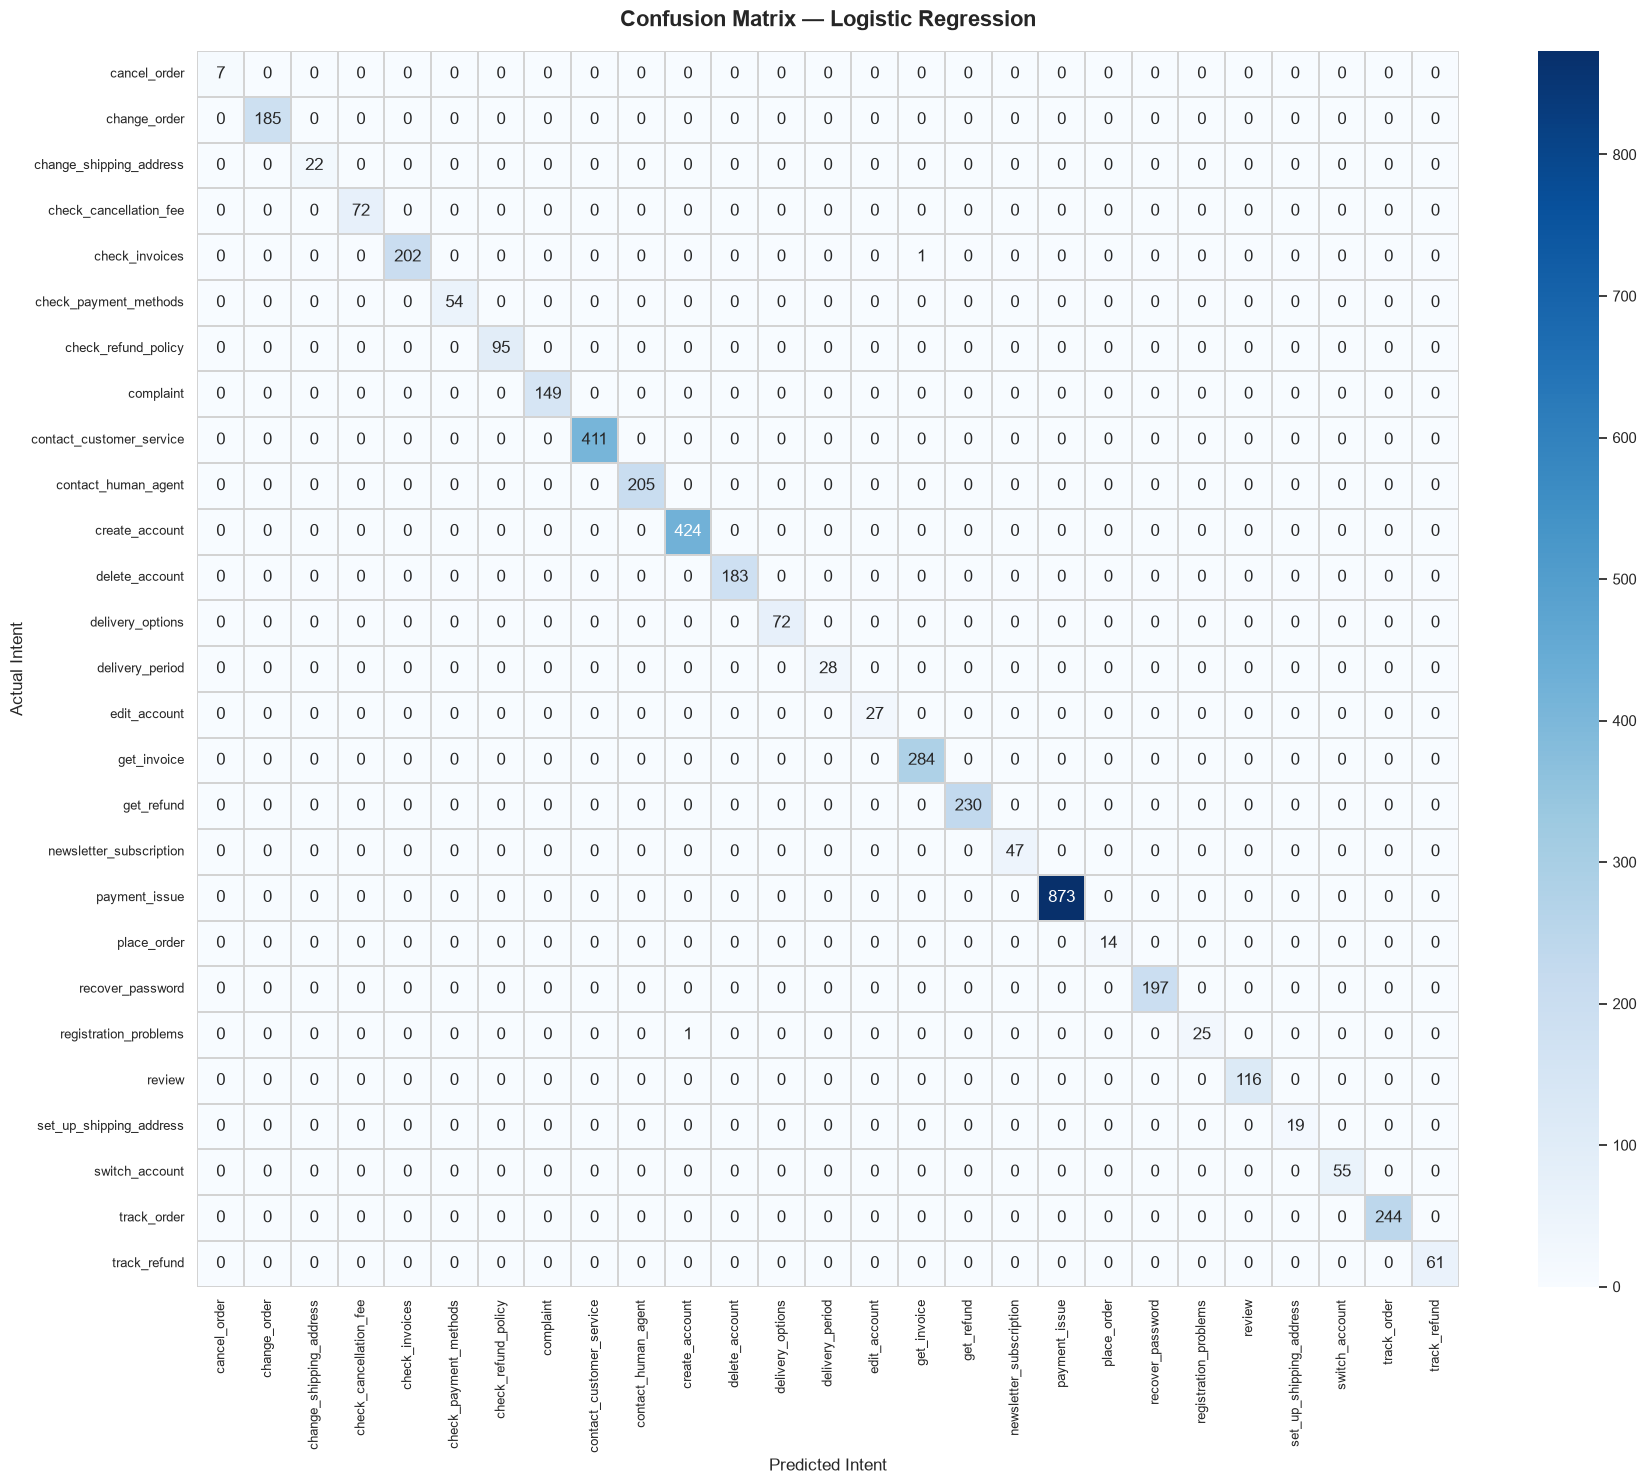

Confusion matrix saved to: ..\reports\figures\logistic_regression_confusion_matrix.png
Correct predictions: 4,301
Misclassifications: 2


In [11]:
intent_labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=intent_labels
)

fig, ax = plt.subplots(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_labels,
    yticklabels=intent_labels,
    linewidths=0.3,
    linecolor="lightgray",
    ax=ax
)

ax.set_title(
    "Confusion Matrix — Logistic Regression",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Predicted Intent", fontsize=12)
ax.set_ylabel("Actual Intent", fontsize=12)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

confusion_matrix_path = figures_dir / "logistic_regression_confusion_matrix.png"

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Confusion matrix saved to: {confusion_matrix_path}")
print(f"Correct predictions: {np.trace(cm):,}")
print(f"Misclassifications: {cm.sum() - np.trace(cm):,}")

#### Analyzing Misclassified Utterances

In [12]:
error_analysis_df = test_df.copy()

error_analysis_df["predicted_intent"] = best_predictions

misclassified_df = (
    error_analysis_df[
        error_analysis_df["intent"] != error_analysis_df["predicted_intent"]
    ]
    .copy()
    .rename(columns={"intent": "actual_intent"})
)

misclassified_df = misclassified_df[
    ["utterance", "actual_intent", "predicted_intent"]
].reset_index(drop=True)

print(f"Total test samples: {len(test_df):,}")
print(f"Correct predictions: {len(test_df) - len(misclassified_df):,}")
print(f"Misclassified samples: {len(misclassified_df):,}")

display(misclassified_df)

Total test samples: 4,303
Correct predictions: 4,301
Misclassified samples: 2


,utterance,actual_intent,predicted_intent
0,where canI seemy bill?,check_invoices,get_invoice
1,I can't create a profile,registration_problems,create_account


#### Observations
- **Only 2 of the 4,303 test utterances are misclassified**, confirming the model's high predictive accuracy on the held-out dataset.
- **Both errors involve closely related intents:** `check_invoices` versus `get_invoice`, and `registration_problems` versus `create_account`.
- **Key Finding:** The remaining classification challenges involve distinguishing semantically overlapping customer requests, particularly when utterances contain irregular spacing or describe unsuccessful actions.

#### Saving Classification Reports and Misclassification Results

In [13]:
class_performance_path = processed_dir / "final_model_classification_report.csv"
misclassifications_path = processed_dir / "final_model_misclassifications.csv"

class_performance_df.to_csv(
    class_performance_path,
    index_label="intent"
)

misclassified_df.to_csv(
    misclassifications_path,
    index=False
)

print("Evaluation artifacts saved successfully.\n")
print(f"Classification report: {class_performance_path}")
print(f"Misclassification results: {misclassifications_path}")
print(f"\nIntent classes documented: {len(class_performance_df)}")
print(f"Misclassified utterances documented: {len(misclassified_df)}")

Evaluation artifacts saved successfully.

Classification report: ..\data\processed\final_model_classification_report.csv
Misclassification results: ..\data\processed\final_model_misclassifications.csv

Intent classes documented: 27
Misclassified utterances documented: 2


## 7. Comparative Error Analysis

#### Comparing Misclassification Counts Across Models

,Model,Correct Predictions,Misclassifications,Error Rate (%)
0,Logistic Regression,4301,2,0.0465
1,Stacking Ensemble,4300,3,0.0697
2,Linear SVM,4299,4,0.0930
3,TextCNN,4283,20,0.4648


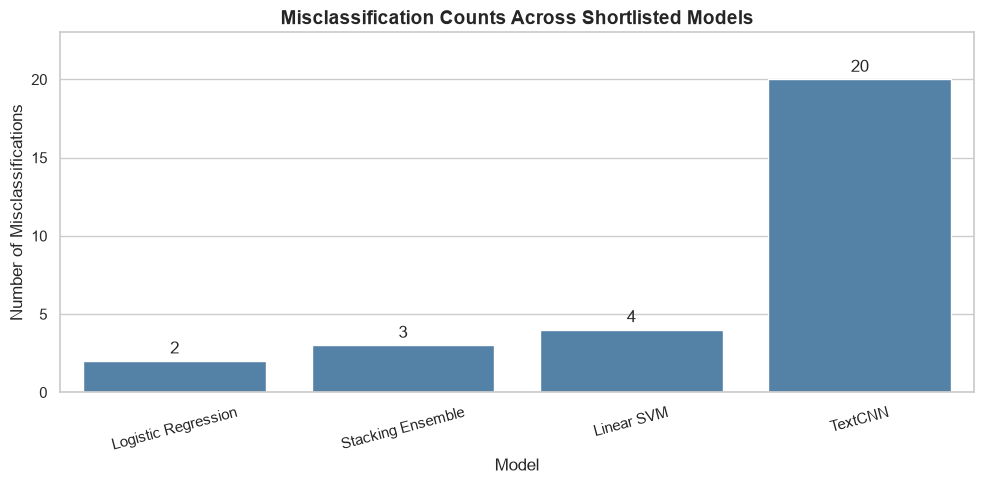

Comparison figure saved to: ..\reports\figures\model_misclassification_comparison.png


In [14]:
error_comparison = []

for model_name, predictions in model_predictions.items():
    incorrect_mask = np.asarray(y_test) != np.asarray(predictions)

    error_comparison.append({
        "Model": model_name,
        "Correct Predictions": int((~incorrect_mask).sum()),
        "Misclassifications": int(incorrect_mask.sum()),
        "Error Rate (%)": round(incorrect_mask.mean() * 100, 4)
    })

error_comparison_df = (
    pd.DataFrame(error_comparison)
    .sort_values("Misclassifications")
    .reset_index(drop=True)
)

display(error_comparison_df)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=error_comparison_df,
    x="Model",
    y="Misclassifications",
    color="steelblue",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_title(
    "Misclassification Counts Across Shortlisted Models",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Number of Misclassifications")
ax.set_ylim(0, error_comparison_df["Misclassifications"].max() * 1.15)

plt.xticks(rotation=15)
plt.tight_layout()

error_comparison_path = figures_dir / "model_misclassification_comparison.png"

plt.savefig(
    error_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Comparison figure saved to: {error_comparison_path}")

#### Observations
- **Logistic Regression records the fewest misclassifications (2)**, corresponding to an error rate of 0.0465%.
- **Stacking Ensemble and Linear SVM make 3 and 4 errors**, respectively, while TextCNN records 20 misclassifications.
- **Key Finding:** Logistic Regression provides the strongest observed accuracy with lower model complexity, although differences among the classical models are small.

#### Analyzing Shared and Unique Model Errors

In [15]:
error_flags = pd.DataFrame({
    model_name: np.asarray(predictions) != y_test.to_numpy()
    for model_name, predictions in model_predictions.items()
})

error_flags["Models Incorrect"] = error_flags.sum(axis=1)

error_overlap_df = test_df.loc[
    error_flags["Models Incorrect"] > 0,
    ["utterance", "intent"]
].copy()

error_overlap_df = error_overlap_df.rename(
    columns={"intent": "Actual Intent"}
)

for model_name in model_predictions:
    error_overlap_df[model_name] = np.asarray(
        model_predictions[model_name]
    )[error_flags["Models Incorrect"] > 0]

error_overlap_df["Models Incorrect"] = (
    error_flags.loc[
        error_flags["Models Incorrect"] > 0,
        "Models Incorrect"
    ].to_numpy()
)

error_overlap_df = (
    error_overlap_df
    .sort_values("Models Incorrect", ascending=False)
    .reset_index(drop=True)
)

print(f"Unique utterances misclassified by at least one model: {len(error_overlap_df)}")
print(f"Utterances misclassified by all four models: {(error_flags['Models Incorrect'] == 4).sum()}")
print(f"Utterances misclassified by exactly one model: {(error_flags['Models Incorrect'] == 1).sum()}")

display(error_overlap_df)

Unique utterances misclassified by at least one model: 21
Utterances misclassified by all four models: 2
Utterances misclassified by exactly one model: 17


,utterance,Actual Intent,Linear SVM,Logistic Regression,Stacking Ensemble,TextCNN,Models Incorrect
0,where canI seemy bill?,check_invoices,get_invoice,get_invoice,get_invoice,get_invoice,4
1,I can't create a profile,registration_problems,create_account,create_account,create_account,create_account,4
2,how long does the delivery take?,delivery_period,check_refund_policy,delivery_period,check_refund_policy,delivery_period,2
3,how can I see y bills?,check_invoices,get_invoice,check_invoices,check_invoices,get_invoice,2
4,could u ask an agent if i could view their apy...,check_payment_methods,check_payment_methods,check_payment_methods,check_payment_methods,check_invoices,1
5,I need help changing my profile,edit_account,edit_account,edit_account,edit_account,delete_account,1
6,how to track my feimbursement,track_refund,track_refund,track_refund,track_refund,track_order,1
7,"i wanna lodge an poinion, what can i do?",review,review,review,review,create_account,1
8,show me your paymebt methods,check_payment_methods,check_payment_methods,check_payment_methods,check_payment_methods,check_refund_policy,1
9,I didn't get an paymentconfirmation,payment_issue,payment_issue,payment_issue,payment_issue,registration_problems,1


#### Observations
- **21 unique test utterances are misclassified by at least one model**, with 2 utterances incorrectly classified by all four models.
- **TextCNN accounts for 17 unique errors**, while the remaining disagreements involve Linear SVM and Stacking Ensemble.
- **Key Finding:** Logistic Regression correctly classifies every utterance handled correctly by the other shortlisted models, providing no evidence of complementary error correction from the ensemble on this test set.

#### Saving Comparative Error Analysis Results

In [16]:
error_overlap_path = processed_dir / "model_error_overlap_analysis.csv"
error_comparison_csv_path = processed_dir / "model_error_comparison.csv"

error_overlap_df.to_csv(
    error_overlap_path,
    index=False
)

error_comparison_df.to_csv(
    error_comparison_csv_path,
    index=False
)

print("Comparative error analysis artifacts saved successfully.\n")
print(f"Error overlap analysis: {error_overlap_path}")
print(f"Model error comparison: {error_comparison_csv_path}")
print(f"\nUnique misclassified utterances: {len(error_overlap_df)}")
print(f"Models compared: {len(model_predictions)}")

Comparative error analysis artifacts saved successfully.

Error overlap analysis: ..\data\processed\model_error_overlap_analysis.csv
Model error comparison: ..\data\processed\model_error_comparison.csv

Unique misclassified utterances: 21
Models compared: 4


## 8. Final Model Selection

#### Selecting the Best-Performing Model

**Selected Model: Logistic Regression with Character-Level TF-IDF**

Logistic Regression is selected as the final model based on its performance across the 4,303 held-out test samples.

The model achieves:

- **Accuracy:** 99.95%
- **Macro Precision:** 0.9998
- **Macro Recall:** 0.9984
- **Macro F1-Score:** 0.9991
- **Weighted F1-Score:** 0.9995
- **Correct Predictions:** 4,301
- **Misclassifications:** 2

#### Justifying the Model Selection

- **Predictive Performance:** Logistic Regression achieves the highest accuracy and macro F1-score among the four shortlisted models.
- **Class-Level Reliability:** The model achieves perfect F1-scores for 23 of the 27 intent classes, with the lowest performance observed for `registration_problems`.
- **Model Simplicity:** The character-level TF-IDF and Logistic Regression pipeline offers a simpler alternative to Stacking Ensemble and TextCNN without sacrificing observed predictive performance.
- **Error Analysis:** The ensemble does not correct either of Logistic Regression's two misclassifications, providing no observed advantage from additional model complexity.

#### Acknowledging Evaluation Limitations

- **Dataset Characteristics:** The Bitext dataset contains structured, template-generated customer support utterances. High test performance may not reflect generalization to naturally occurring customer conversations.
- **Limited Class Support:** Several intents have relatively few test examples, making their individual performance estimates less reliable.
- **Small Performance Differences:** Differences among the classical models involve only a few predictions and should not be interpreted as statistically conclusive superiority.
- **Deep Learning Comparison:** TextCNN was trained using a separate training/validation partition, whereas the final classical models were fitted using the full training dataset. The comparison therefore reflects the saved models rather than identical training conditions.

**Final Decision:** Logistic Regression with Character-Level TF-IDF is selected as the preferred model for this project, based on its held-out predictive performance, computational efficiency, and lower model complexity.

## 9. Evaluation Summary

#### Summarizing Model Evaluation Findings

The evaluation of four shortlisted models demonstrates strong predictive performance across 27 customer support intents, with Logistic Regression emerging as the preferred model.

**Key Findings:**

- **Model Performance:** Logistic Regression with Character-Level TF-IDF achieves the highest test accuracy (99.95%) and macro F1-score (0.9991), correctly classifying 4,301 of 4,303 utterances.
- **Classification Reliability:** The model achieves perfect F1-scores across 23 intents, with the remaining errors involving closely related customer support requests.
- **Model Comparison:** Stacking Ensemble, Linear SVM, and TextCNN demonstrate strong performance, but none improves upon Logistic Regression on the held-out test dataset.
- **Generalization Considerations:** The highly structured nature of the dataset and limited support for certain intents warrant further validation using independent, real-world customer conversations.

**Conclusion:** The selected Logistic Regression pipeline provides an effective and computationally efficient approach to multiclass customer support intent classification. Its strong predictive performance and relatively simple architecture make it suitable for subsequent model explainability analysis, while external validation remains necessary before real-world deployment.